In [1]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

In [85]:
df = pd.read_parquet('../../dataset/imdb.parquet')
scaler = StandardScaler()

In [89]:
df.shape

(141389, 8)

In [86]:
test = df.rating.values
val = scaler.fit_transform(test.reshape(-1, 1))

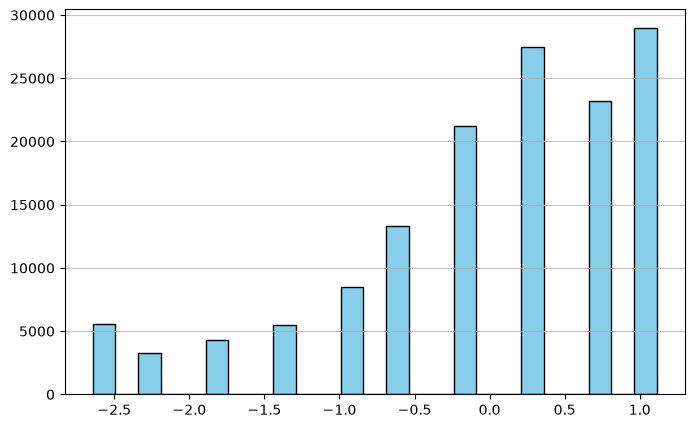

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(val, bins=25, color='skyblue', edgecolor='black')

plt.grid(axis='y', alpha=0.75)
plt.show()

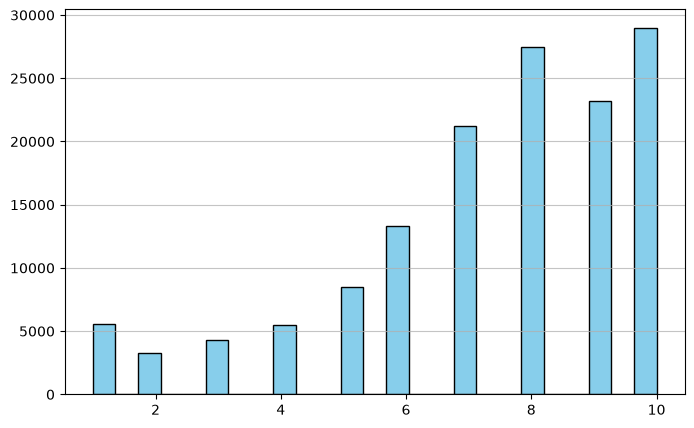

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist( df.rating.values, bins=25, color='skyblue', edgecolor='black')

plt.grid(axis='y', alpha=0.75)
plt.show()


In [ ]:
import numpy as np
import json
import os

root = "dataset/imdb_data"
cfg = json.load(open(os.path.join(root, "config_stats.json")))
U = cfg["user_num"]         # embedding size used by model
I = cfg["item_num"]
V = cfg["vocab_size"]

def max2(path):
    a = np.load(path, allow_pickle=True)
    a = np.array(a)
    return a.min(), a.max(), a.shape, a.dtype

print("CONFIG:", cfg)

# (uid,iid) pairs
mn, mx, shp, dt = max2(os.path.join(root, "train/Train.npy"))
pairs = np.load(os.path.join(root, "train/Train.npy"))
pairs = np.array(pairs)
print("Train.npy uid min/max:", pairs[:,0].min(), pairs[:,0].max(), "limit:", U-1)
print("Train.npy iid min/max:", pairs[:,1].min(), pairs[:,1].max(), "limit:", I-1)

# word indices tensors
mn, mx, shp, dt = max2(os.path.join(root, "train/userReview2Index.npy"))
print("userReview2Index min/max:", mn, mx, "limit:", V-1, "shape:", shp)

mn, mx, shp, dt = max2(os.path.join(root, "train/itemReview2Index.npy"))
print("itemReview2Index min/max:", mn, mx, "limit:", V-1, "shape:", shp)

# neighbor id lists (these hit embeddings too in some models)
mn, mx, shp, dt = max2(os.path.join(root, "train/user_item2id.npy"))
print("user_item2id min/max:", mn, mx, "limit:", I-1, "shape:", shp)

mn, mx, shp, dt = max2(os.path.join(root, "train/item_user2id.npy"))
print("item_user2id min/max:", mn, mx, "limit:", U-1, "shape:", shp)


In [ ]:
user_id = np.load(root+"/train/userReview2Index.npy")

In [ ]:
user_id[7145]

In [ ]:
import numpy as np

y = np.load("dataset/imdb_data/train/Train_Score.npy")
print("scores dtype:", y.dtype)
print("nan:", np.isnan(y).sum(), "inf:", np.isinf(y).sum(), "min:", np.nanmin(y), "max:", np.nanmax(y))


In [ ]:
u_doc = np.load("dataset/imdb_data/train/userFineDoc.npy", allow_pickle=True)
print("userFineDoc nan:", np.isnan(u_doc).sum(), "inf:", np.isinf(u_doc).sum())

In [ ]:
df.head()